# Linear Regression Training Project: Digital Insomnia — Screen Habits & Sleep

In this project, we work with a simulated dataset containing information about individuals' screen habits, lifestyle factors, environmental conditions, and next-day fatigue scores.

The dataset includes the following variables:

- **Age:** Age of the individual in years.
- **Screen Time Before Bed:** Time spent using screens before bedtime, in minutes.
- **Screen Brightness:** Screen brightness level, expressed as a percentage.
- **Caffeine Intake:** Caffeine consumption in milligrams.
- **Physical Activity:** Duration of physical activity, in minutes.
- **Room Temperature:** Room temperature in degrees Fahrenheit.
- **Ambient Noise:** Environmental noise level in decibels.
- **Next-Day Fatigue Score:** Numerical measure of fatigue, used as our target variable.

In this project, we aim to determine which individual predictor has the strongest linear relationship with next-day fatigue. We will use Simple Linear Regression Models (SLRMs), exploratory data analysis, statistical significance testing, and model evaluation metrics to compare the predictive performance of seven models.

**Note:** The dataset is simulated and intended for educational purposes. The results describe patterns in this dataset and do not establish real-world causal relationships.

In [11]:
from google.colab import files
uploaded = files.upload()

Saving sleep.csv to sleep.csv


In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

## Getting the Data

We begin by loading the dataset and inspecting its structure. We examine the first few observations, data types, missing values, and descriptive statistics to understand the variables before proceeding with the analysis.

In [12]:
df  = pd.read_csv("sleep.csv")

In [13]:
df.head()

,user_id,age,screen_time_before_bed_min,screen_brightness_pct,caffeine_intake_mg,physical_activity_min,room_temperature_f,ambient_noise_db,next_day_fatigue_score
0,1,32,102,100,264,73,73.5,32.6,8.85
1,2,26,14,87,18,25,66.8,44.3,2.98
2,3,34,58,76,62,48,68.0,45.6,3.90
3,4,43,48,56,42,9,72.3,42.3,4.81
4,5,25,29,96,78,5,80.1,10.0,3.88


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     8500 non-null   int64  
 1   age                         8500 non-null   int64  
 2   screen_time_before_bed_min  8500 non-null   int64  
 3   screen_brightness_pct       8500 non-null   int64  
 4   caffeine_intake_mg          8500 non-null   int64  
 5   physical_activity_min       8500 non-null   int64  
 6   room_temperature_f          8500 non-null   float64
 7   ambient_noise_db            8500 non-null   float64
 8   next_day_fatigue_score      8500 non-null   float64
dtypes: float64(3), int64(6)
memory usage: 597.8 KB


In [15]:
df.describe()

,user_id,age,screen_time_before_bed_min,screen_brightness_pct,caffeine_intake_mg,physical_activity_min,room_temperature_f,ambient_noise_db,next_day_fatigue_score
count,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000
mean,4250.500000,28.099647,53.744118,68.770235,79.650000,29.761882,70.083506,34.972753,4.549893
std,2453.882977,9.007551,35.349292,18.923090,78.348824,30.000228,3.962443,10.011726,0.954115
min,1.000000,16.000000,5.000000,5.000000,0.000000,0.000000,58.000000,10.000000,1.070000
25%,2125.750000,21.000000,29.000000,56.000000,22.000000,8.000000,67.400000,28.200000,3.890000
50%,4250.500000,27.000000,45.000000,69.000000,55.500000,20.000000,70.100000,35.000000,4.520000
75%,6375.250000,34.000000,68.000000,83.000000,113.000000,42.000000,72.700000,41.500000,5.180000
max,8500.000000,65.000000,240.000000,100.000000,500.000000,180.000000,82.000000,70.000000,8.850000


## Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the distribution of the variables and their relationships with next-day fatigue.

We first examine the Pearson correlation coefficients between each predictor and the target variable. These coefficients measure the direction and strength of linear relationships, with positive values indicating that higher predictor values tend to be associated with higher fatigue scores.

We will use these results as an initial guide for comparing the individual regression models.

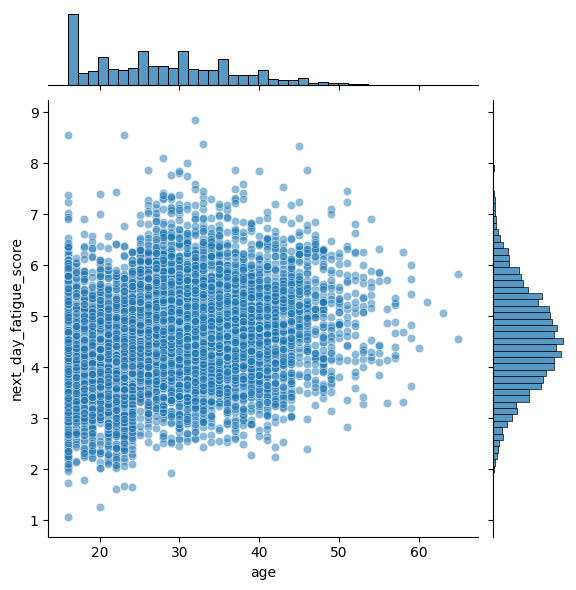

In [17]:
#EDA

sns.jointplot(x = "age", y = "next_day_fatigue_score", data = df, alpha = 0.5)

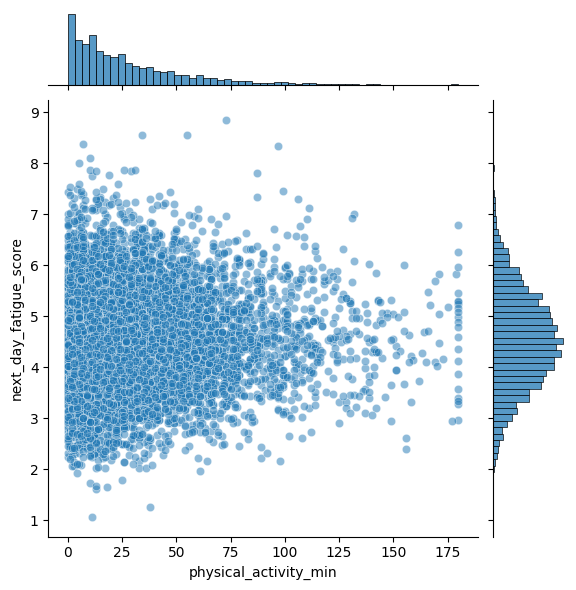

In [22]:
sns.jointplot(x = "physical_activity_min", y = "next_day_fatigue_score", data = df, alpha = 0.5)

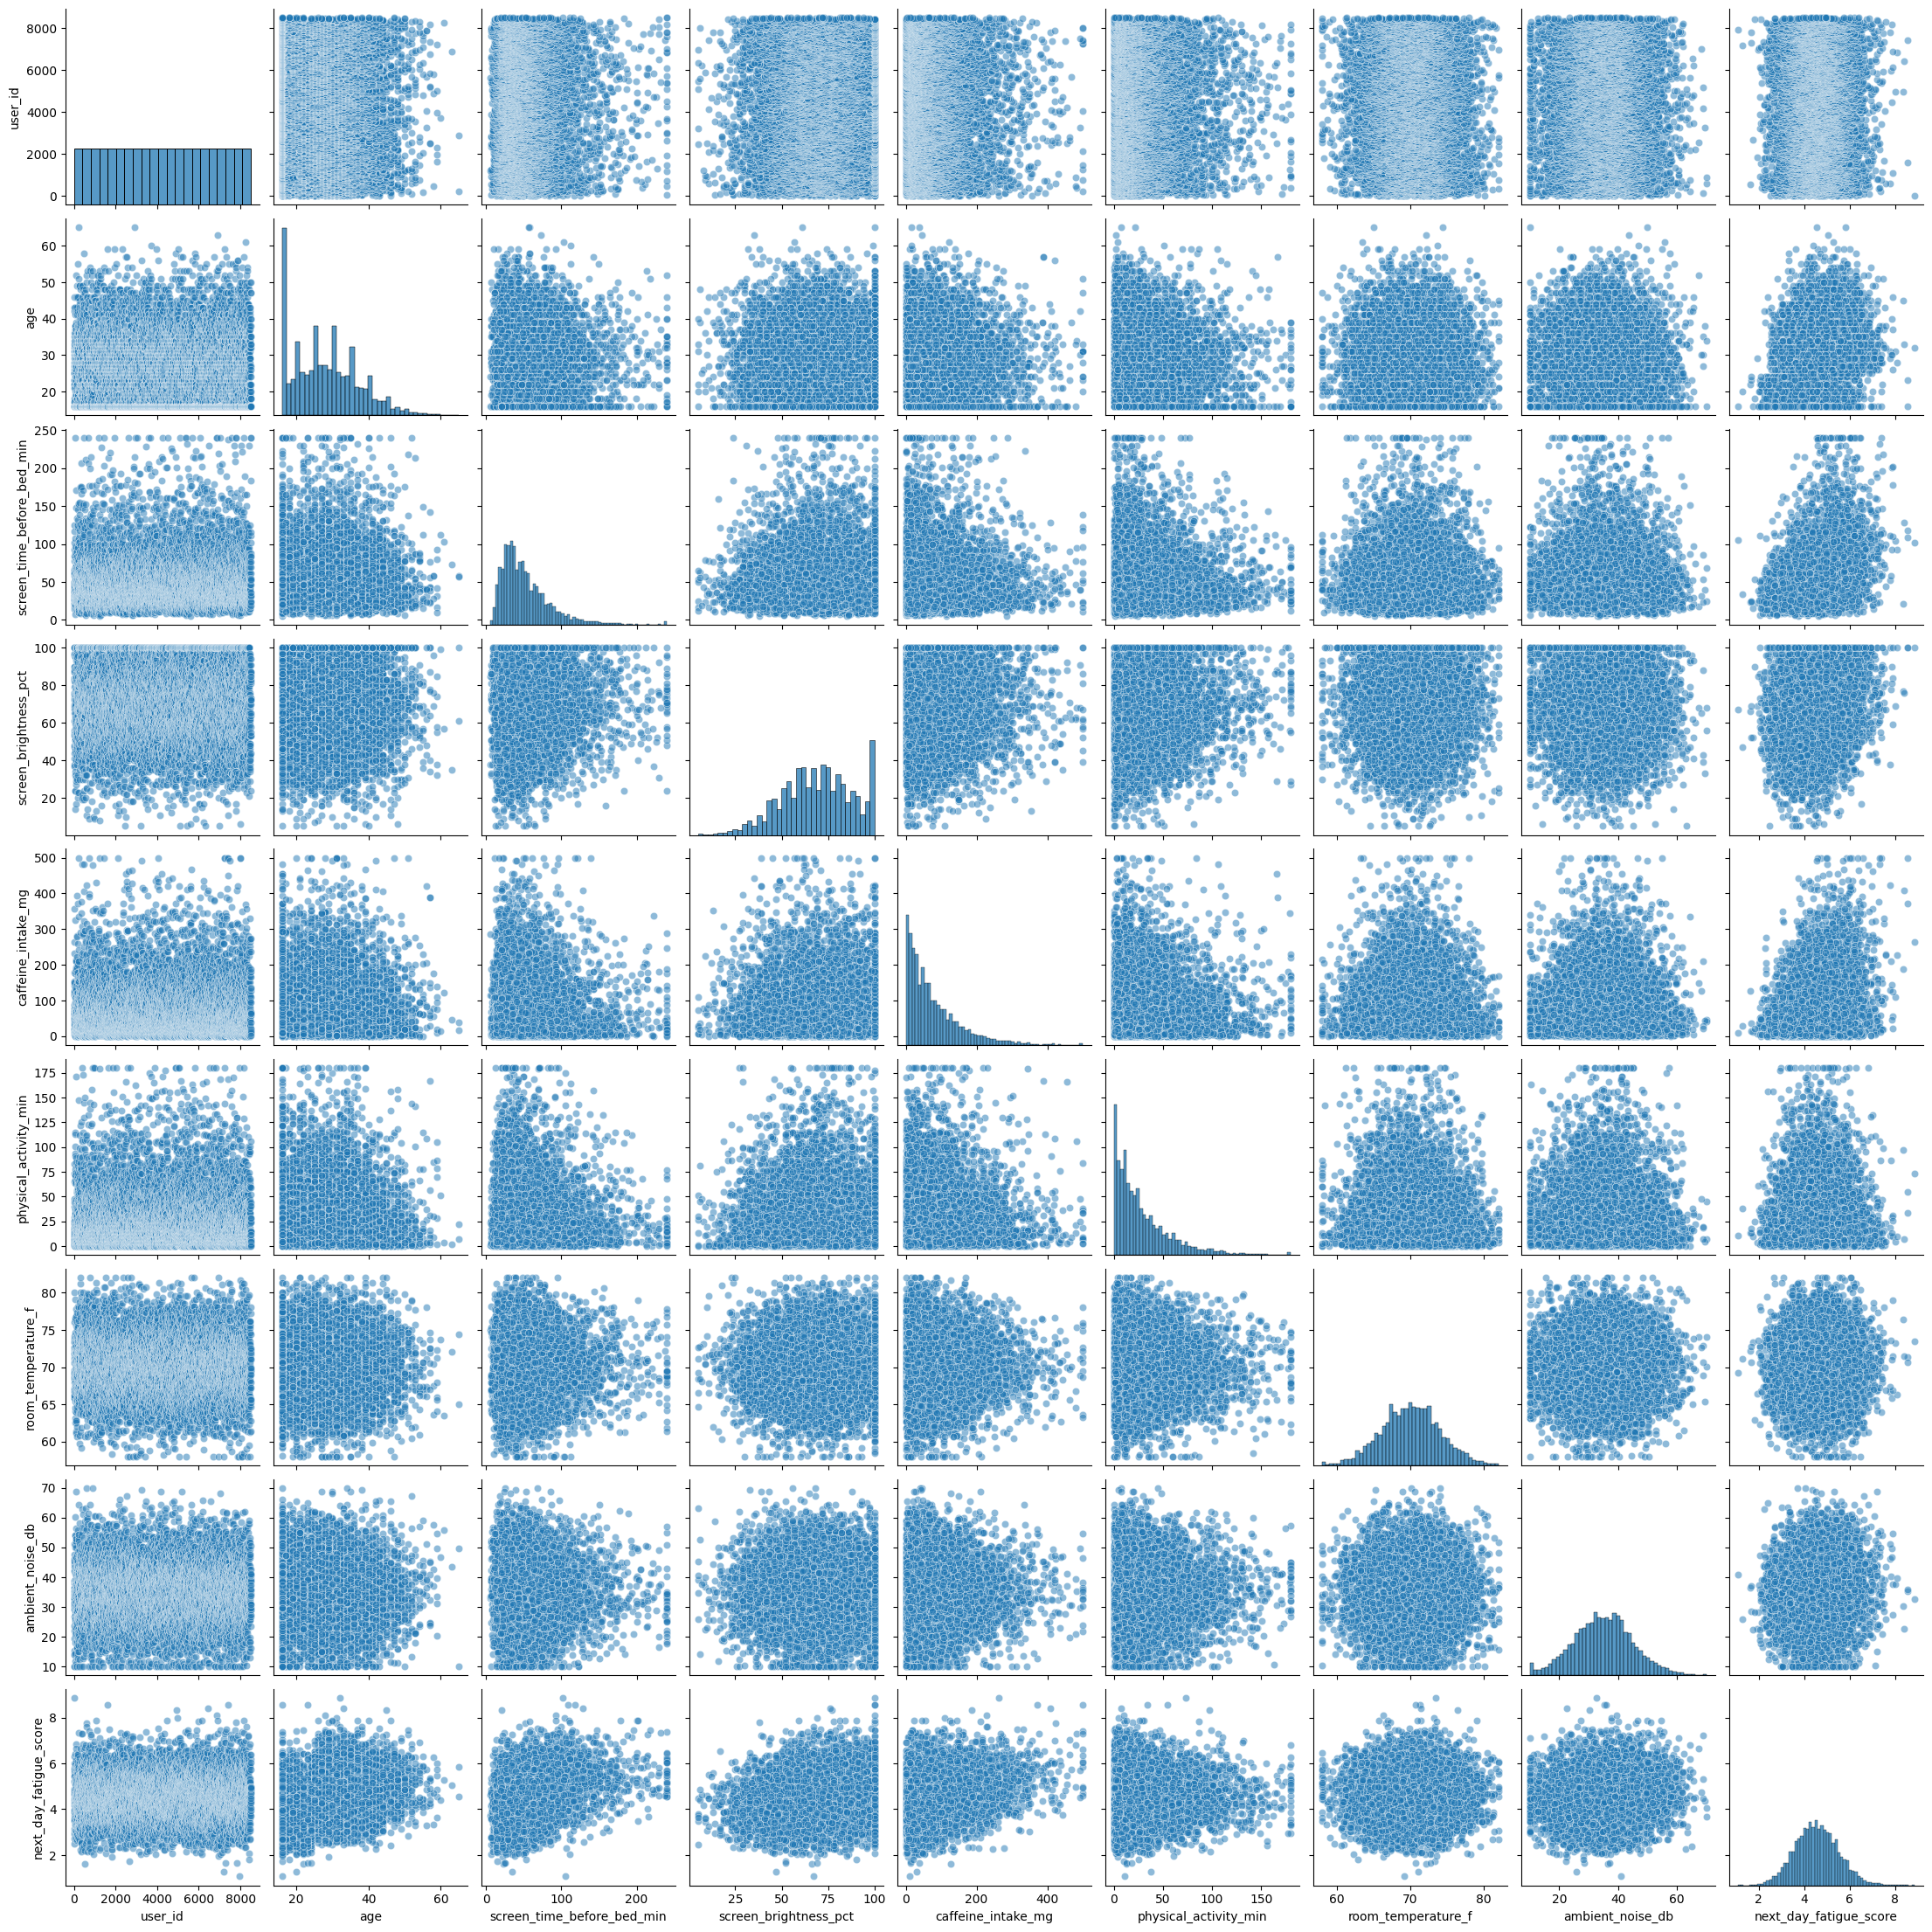

In [21]:
sns.pairplot(df, kind = "scatter", plot_kws= {'alpha' : 0.5})

In [23]:
# Define predictors and target
predictors = [
    "age",
    "screen_time_before_bed_min",
    "screen_brightness_pct",
    "caffeine_intake_mg",
    "physical_activity_min",
    "room_temperature_f",
    "ambient_noise_db"
]

target = "next_day_fatigue_score"

In [24]:
# Calculate Pearson correlations with the target
correlations = (
    df[predictors + [target]]
    .corr(method="pearson")[target]
    .drop(target)
    .to_frame(name="Pearson_r")
)

In [25]:
correlations["Absolute_r"] = correlations["Pearson_r"].abs()
correlations = correlations.sort_values("Absolute_r", ascending=False)

display(correlations)

,Pearson_r,Absolute_r
screen_time_before_bed_min,0.336067,0.336067
age,0.278334,0.278334
caffeine_intake_mg,0.261541,0.261541
screen_brightness_pct,0.176128,0.176128
ambient_noise_db,0.067587,0.067587
physical_activity_min,0.016990,0.016990
room_temperature_f,0.011141,0.011141


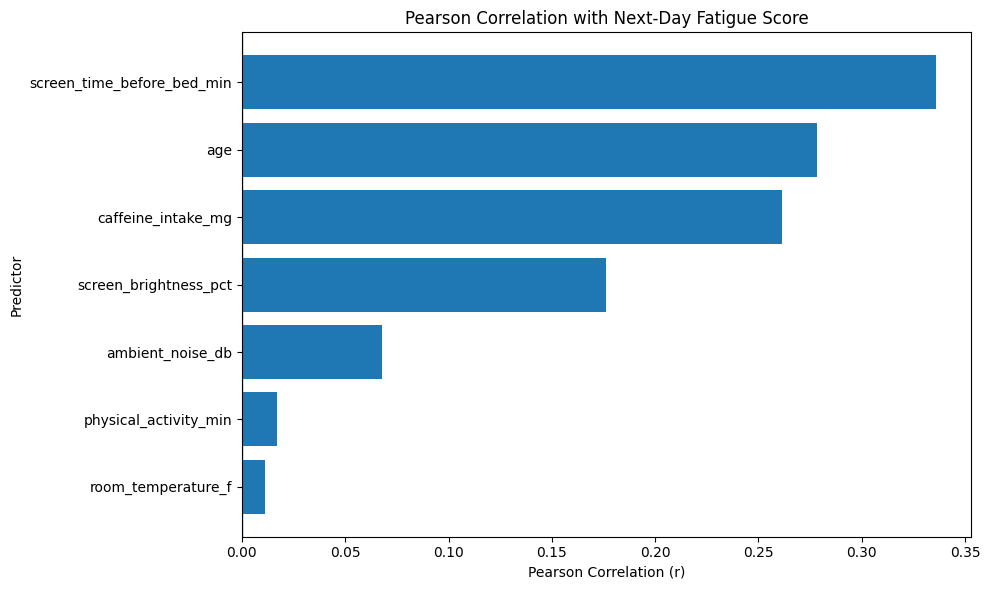

In [26]:
# Sort correlations from strongest to weakest
plot_data = correlations.sort_values("Pearson_r")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index,
    plot_data["Pearson_r"]
)

plt.axvline(x=0, linewidth=1)
plt.xlabel("Pearson Correlation (r)")
plt.ylabel("Predictor")
plt.title("Pearson Correlation with Next-Day Fatigue Score")
plt.tight_layout()
plt.show()

In [48]:
alpha = 0.05

results = []

for predictor in predictors:
    r, p_value = pearsonr(df[predictor], df[target])

    results.append({
        "Predictor": predictor,
        "Pearson_r": r,
        "p_value": p_value,
        "Decision": (
            "Reject H0" if p_value < alpha
            else "Fail to reject H0"
        )
    })

hypothesis_results = pd.DataFrame(results)
hypothesis_results = hypothesis_results.sort_values(
    "Pearson_r",
    key=lambda x: x.abs(),
    ascending=False
)

display(hypothesis_results)

,Predictor,Pearson_r,p_value,Decision
1,screen_time_before_bed_min,0.336067,1.821837e-223,Reject H0
0,age,0.278334,4.947120e-151,Reject H0
3,caffeine_intake_mg,0.261541,5.861335e-133,Reject H0
2,screen_brightness_pct,0.176128,3.461754e-60,Reject H0
6,ambient_noise_db,0.067587,4.447372e-10,Reject H0
4,physical_activity_min,0.016990,1.172885e-01,Fail to reject H0
5,room_temperature_f,0.011141,3.044099e-01,Fail to reject H0


## Splitting the Data

Before training the models, we divide the dataset into training and testing sets using a 70:30 split.

The training set is used to estimate the regression coefficients, while the testing set is reserved for evaluating predictive performance on observations that were not used during training.

We exclude `user_id` because it is an identifier rather than a meaningful predictor. The target variable is `next_day_fatigue_score`, and the seven selected predictors are evaluated individually.

In [32]:
# Define predictors and target
predictors = [
    "age",
    "screen_time_before_bed_min",
    "screen_brightness_pct",
    "caffeine_intake_mg",
    "physical_activity_min",
    "room_temperature_f",
    "ambient_noise_db"
]

target = "next_day_fatigue_score"

# Split the dataset: 70% training, 30% testing
train_df, test_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)

# Display dataset sizes
print("Original dataset:", df.shape)
print("Training set:", train_df.shape)
print("Testing set:", test_df.shape)

print(f"\nTraining proportion: {len(train_df) / len(df) * 100:.1f}%")
print(f"Testing proportion: {len(test_df) / len(df) * 100:.1f}%")

Original dataset: (8500, 9)
Training set: (5950, 9)
Testing set: (2550, 9)

Training proportion: 70.0%
Testing proportion: 30.0%


## Training the Simple Linear Regression Models

We train seven separate Simple Linear Regression Models (SLRMs), with each model using one predictor to estimate next-day fatigue.

Each model follows the equation:

\[
\hat{Y} = b_0 + b_1X
\]

where \(\hat{Y}\) is the predicted fatigue score, \(b_0\) is the intercept, \(b_1\) is the slope coefficient, and \(X\) is the selected predictor.

We compare the estimated coefficients, training \(R^2\), and p-values to examine each model's fit and the statistical significance of its slope.

In [33]:
slrm_models = {}
slrm_results = []

for predictor in predictors:
    # Training data only
    X_train = sm.add_constant(train_df[[predictor]])
    y_train = train_df[target]

    # Fit the SLRM
    model = sm.OLS(y_train, X_train).fit()

    slrm_models[predictor] = model

    slrm_results.append({
        "Predictor": predictor,
        "Intercept": model.params["const"],
        "Slope": model.params[predictor],
        "R_squared": model.rsquared,
        "P_value_slope": model.pvalues[predictor]
    })

# Display results, ranked by training R-squared
train_results_df = pd.DataFrame(slrm_results)

display(
    train_results_df
    .sort_values("R_squared", ascending=False)
    .round(6)
)

,Predictor,Intercept,Slope,R_squared,P_value_slope
1,screen_time_before_bed_min,4.068279,0.009159,0.112107,0.000000
0,age,3.754391,0.028683,0.072348,0.000000
3,caffeine_intake_mg,4.304163,0.003212,0.070091,0.000000
2,screen_brightness_pct,3.941569,0.009021,0.032068,0.000000
6,ambient_noise_db,4.334861,0.006503,0.004619,0.000000
4,physical_activity_min,4.546173,0.000527,0.000267,0.207615
5,room_temperature_f,4.487080,0.001065,0.000019,0.734955


In [36]:
import math

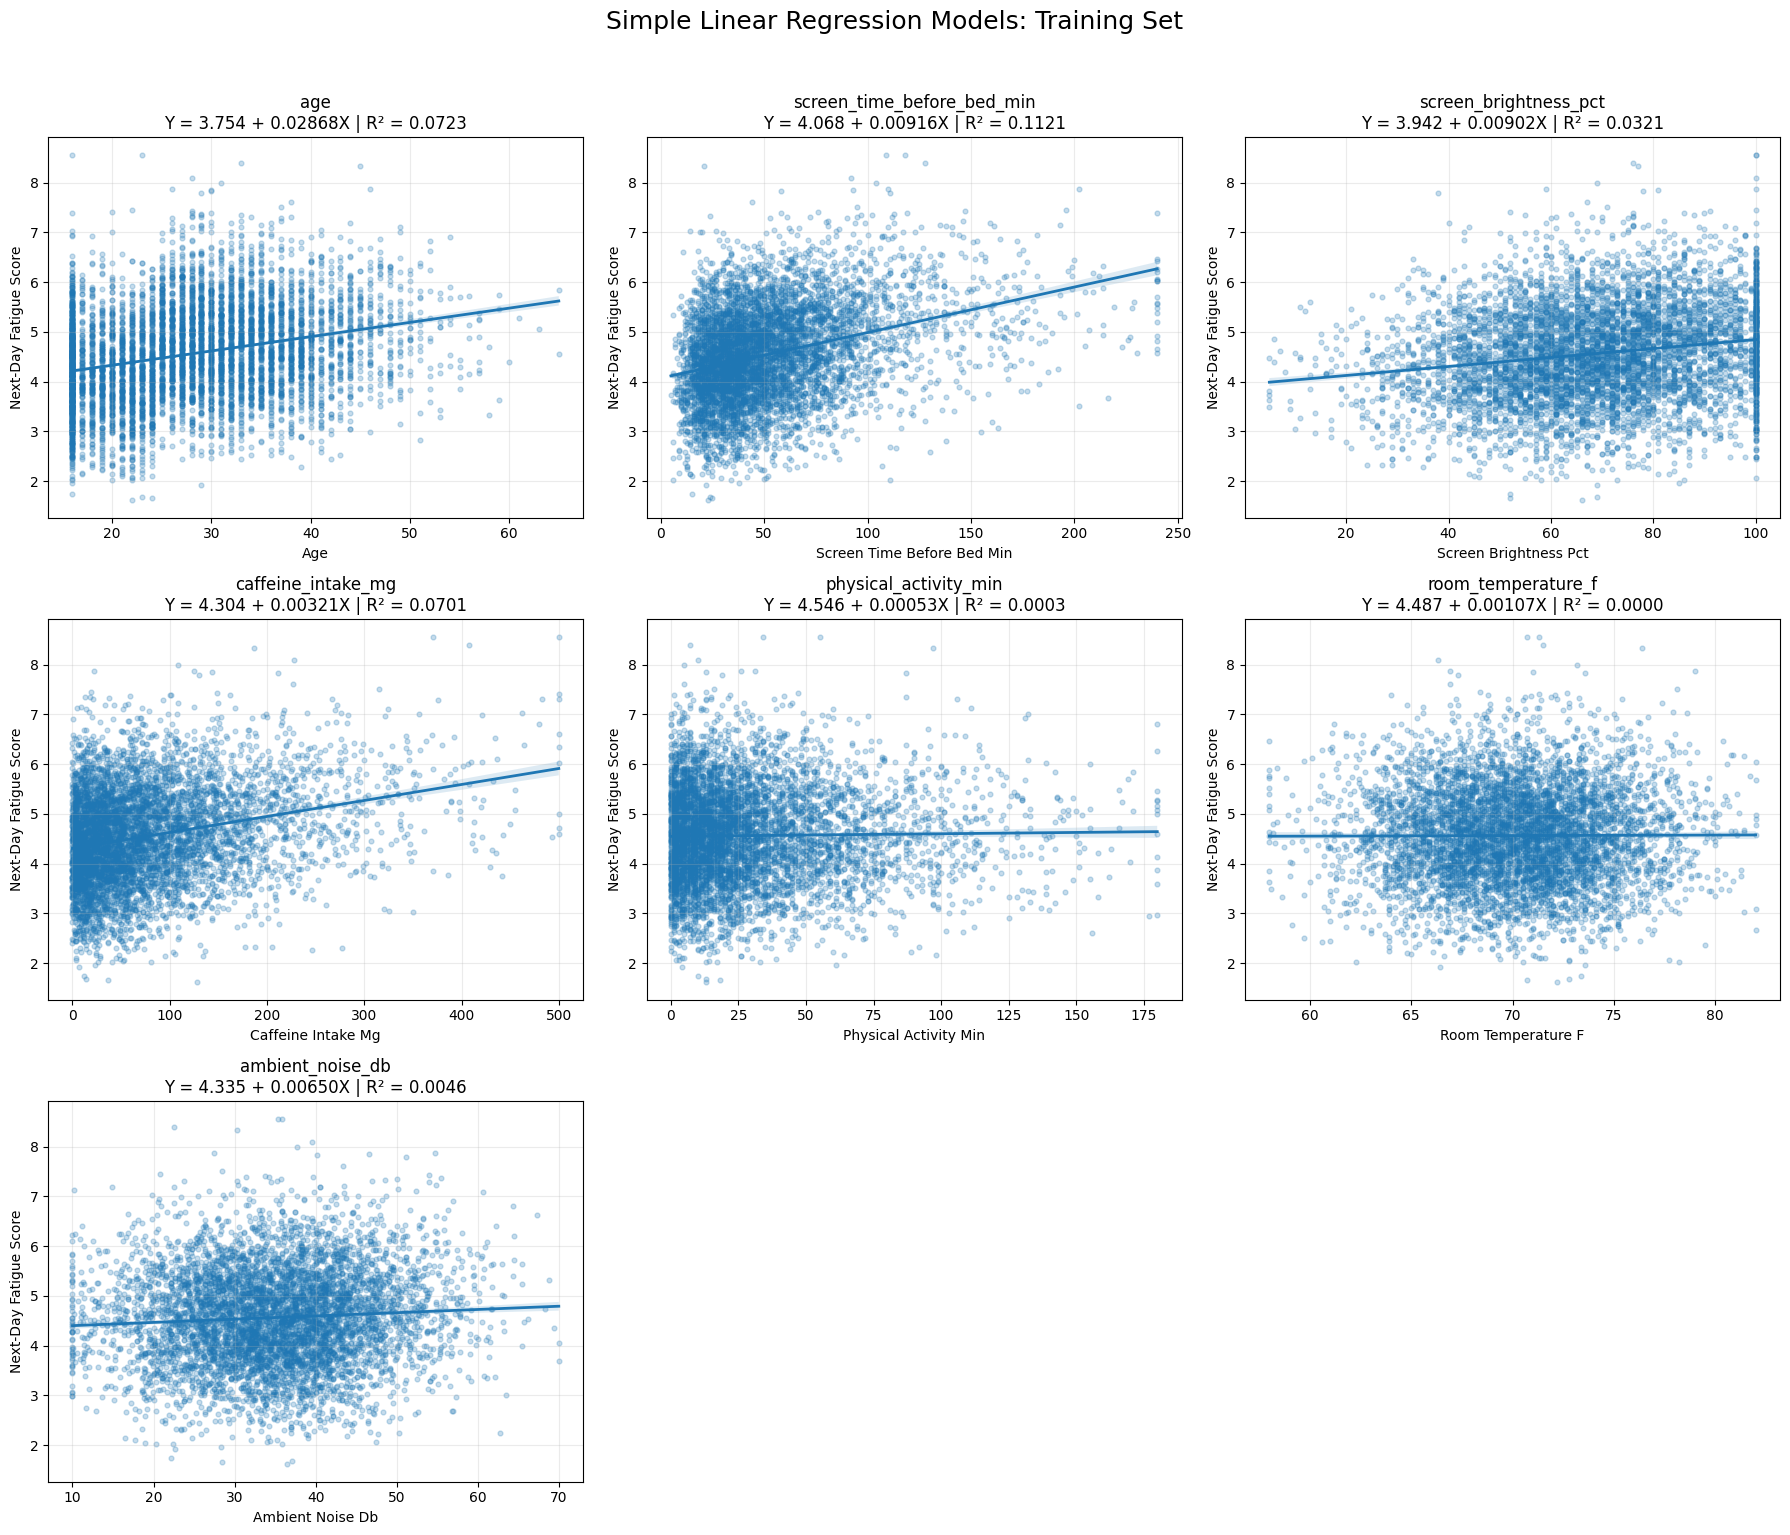

In [37]:
# Create a 3 x 3 grid for the seven SLRM graphs
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, predictor in enumerate(predictors):
    ax = axes[i]

    # Scatterplot and regression line fitted on training data
    sns.regplot(
        data=train_df,
        x=predictor,
        y=target,
        ax=ax,
        scatter_kws={"alpha": 0.25, "s": 12},
        line_kws={"linewidth": 2},
        ci=95
    )

    # Get the fitted model's coefficients and R-squared
    model = slrm_models[predictor]
    intercept = model.params["const"]
    slope = model.params[predictor]
    r_squared = model.rsquared

    ax.set_title(
        f"{predictor}\n"
        f"Y = {intercept:.3f} + {slope:.5f}X | "
        f"R² = {r_squared:.4f}"
    )
    ax.set_xlabel(predictor.replace("_", " ").title())
    ax.set_ylabel("Next-Day Fatigue Score")
    ax.grid(alpha=0.25)

# Hide the two unused subplot spaces
for j in range(len(predictors), len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    "Simple Linear Regression Models: Training Set",
    fontsize=18,
    y=1.02
)

plt.tight_layout()
plt.show()

## Predicting Test Data

After training the models, we use the testing set to generate predicted fatigue scores. Comparing these predictions with the actual scores allows us to assess how well each model performs on unseen observations.

We evaluate each model using test \(R^2\), Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

In [38]:
predictions_df = pd.DataFrame(index=test_df.index)

# Actual observed fatigue scores
predictions_df["Actual_Fatigue_Score"] = test_df[target]

# Predict using each fitted SLRM
for predictor, model in slrm_models.items():
    X_test = sm.add_constant(test_df[[predictor]], has_constant="add")
    predictions_df[f"Predicted_{predictor}"] = model.predict(X_test)

# Display the first 10 predictions
display(predictions_df.head(10).round(3))

,Actual_Fatigue_Score,Predicted_age,Predicted_screen_time_before_bed_min,Predicted_screen_brightness_pct,Predicted_caffeine_intake_mg,Predicted_physical_activity_min,Predicted_room_temperature_f,Predicted_ambient_noise_db
6244,5.99,4.357,4.938,4.465,5.650,4.568,4.559,4.567
6813,4.95,4.213,4.664,4.519,5.268,4.561,4.561,4.481
7019,6.66,4.558,4.920,4.699,4.417,4.582,4.565,4.536
5537,4.41,4.443,4.499,4.329,4.587,4.554,4.560,4.630
6307,4.87,4.787,4.270,4.203,4.584,4.556,4.561,4.604
2794,4.74,4.529,5.195,4.429,4.445,4.555,4.566,4.575
2221,2.64,4.357,4.490,4.636,4.346,4.553,4.560,4.525
5282,5.09,4.844,4.490,4.708,5.011,4.546,4.567,4.599
2833,5.14,4.471,4.416,4.582,4.365,4.599,4.562,4.561
4514,3.46,4.500,4.371,4.420,4.494,4.554,4.563,4.400


In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [43]:
evaluation_results = []

for predictor in slrm_models.keys():

    # Actual and predicted values
    y_actual = predictions_df["Actual_Fatigue_Score"]
    y_predicted = predictions_df[f"Predicted_{predictor}"]

    # Calculate evaluation metrics
    evaluation_results.append({
        "Predictor": predictor,
        "Test_R_squared": r2_score(y_actual, y_predicted),
        "MAE": mean_absolute_error(y_actual, y_predicted),
        "RMSE": np.sqrt(mean_squared_error(y_actual, y_predicted))
    })

# Rank models by RMSE, lowest error first
evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df = evaluation_df.sort_values(
    "RMSE", ascending=True
).reset_index(drop=True)

display(evaluation_df.round(6))

,Predictor,Test_R_squared,MAE,RMSE
0,screen_time_before_bed_min,0.113411,0.699648,0.885130
1,age,0.088179,0.712282,0.897636
2,caffeine_intake_mg,0.062745,0.719282,0.910069
3,screen_brightness_pct,0.026702,0.738363,0.927403
4,ambient_noise_db,0.002633,0.745301,0.938800
5,physical_activity_min,-0.001434,0.747397,0.940712
6,room_temperature_f,-0.001541,0.747379,0.940763


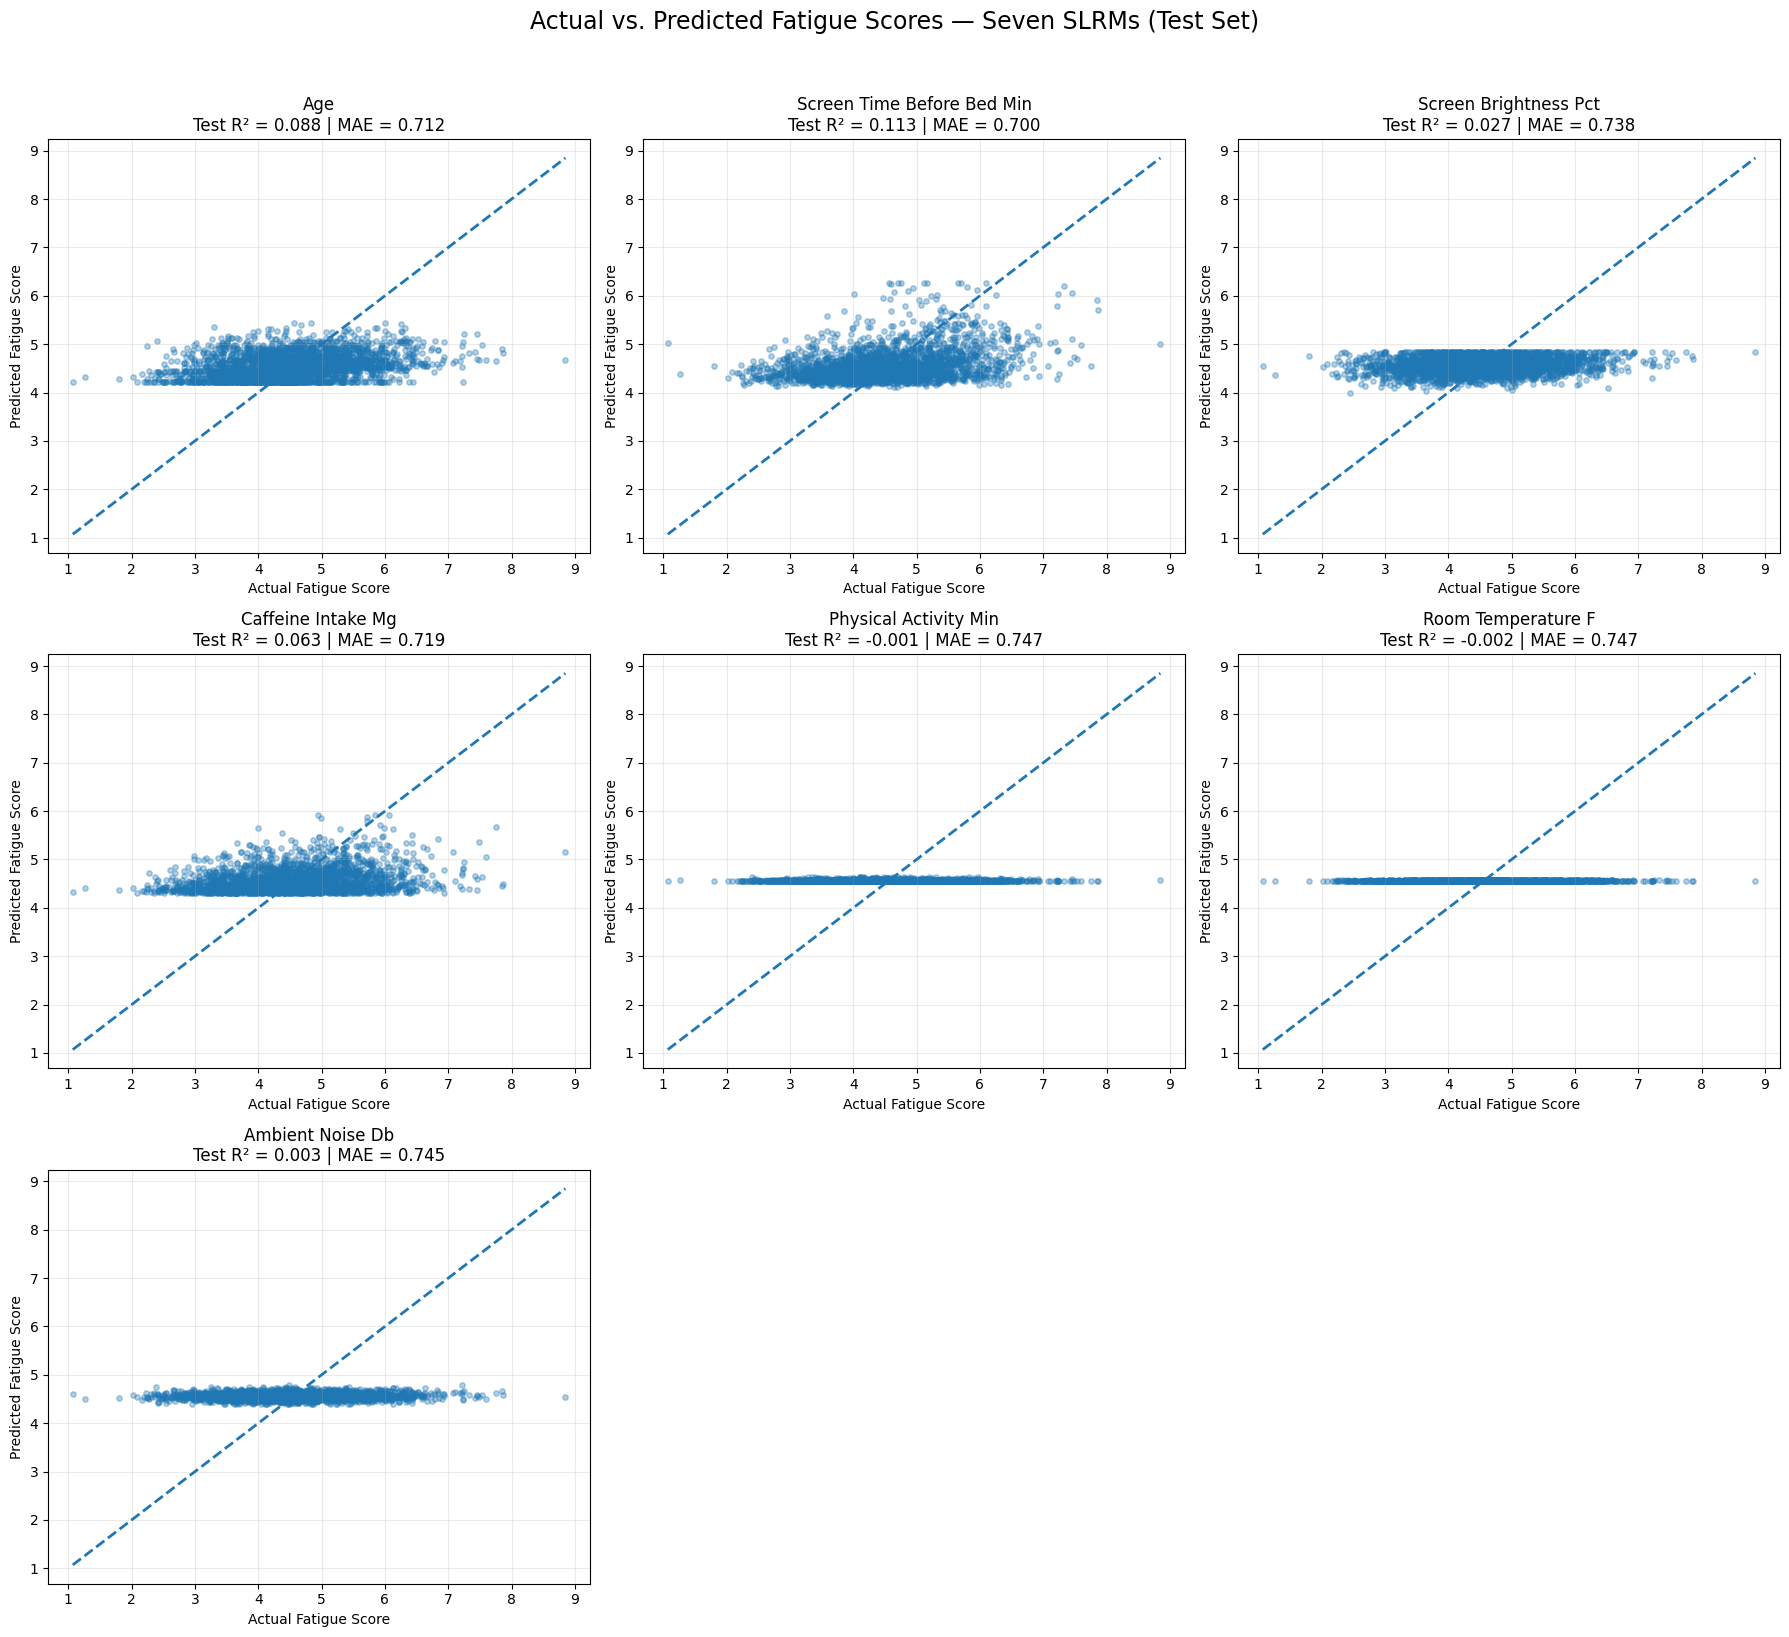

In [44]:
predictors = list(slrm_models.keys())

# Create a 3 x 3 grid for the seven models
fig, axes = plt.subplots(3, 3, figsize=(18, 16))
axes = axes.flatten()

actual = predictions_df["Actual_Fatigue_Score"]

for i, predictor in enumerate(predictors):
    ax = axes[i]
    predicted = predictions_df[f"Predicted_{predictor}"]

    # Plot actual vs predicted
    ax.scatter(actual, predicted, alpha=0.35, s=15)

    # Perfect prediction reference line
    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())
    ax.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
        linewidth=2
    )

    # Get test-set evaluation metrics
    r2 = r2_score(actual, predicted)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    ax.set_title(
        f"{predictor.replace('_', ' ').title()}\n"
        f"Test R² = {r2:.3f} | MAE = {mae:.3f}"
    )
    ax.set_xlabel("Actual Fatigue Score")
    ax.set_ylabel("Predicted Fatigue Score")
    ax.grid(alpha=0.25)

# Hide unused subplot spaces
for j in range(len(predictors), len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    "Actual vs. Predicted Fatigue Scores — Seven SLRMs (Test Set)",
    fontsize=17,
    y=1.02
)

plt.tight_layout()
plt.show()

## Evaluation of the Models

We compare the seven models using their test-set performance.

- **Test R²:** Measures the proportion of variation explained relative to predicting the mean of the test target values. A negative value means the model performs worse than this baseline.
- **MAE:** Measures the average absolute prediction error.
- **RMSE:** Measures prediction error while penalizing larger errors more heavily.

For models evaluated on the same test observations and target scale, higher test \(R^2\) and lower MAE and RMSE generally indicate better predictive performance.

In [46]:
# Display the comparison table without the extra DataFrame index
display(
    comparison_df.style
    .format({
        "Intercept": "{:.4f}",
        "Slope_Coefficient": "{:.6f}",
        "Training_R2": "{:.4f}",
        "Training_P_value": "{}",
        "Test_R_squared": "{:.4f}",
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}"
    })
    .hide(axis="index")
)

Rank,Predictor,Intercept,Slope_Coefficient,Training_R2,Training_P_value,Test_R_squared,MAE,RMSE
1,screen_time_before_bed_min,4.0683,0.009159,0.1121,8.189e-156,0.1134,0.6996,0.8851
2,age,3.7544,0.028683,0.0723,3.866e-99,0.0882,0.7123,0.8976
3,caffeine_intake_mg,4.3042,0.003212,0.0701,5.400e-96,0.0627,0.7193,0.9101
4,screen_brightness_pct,3.9416,0.009021,0.0321,4.600e-44,0.0267,0.7384,0.9274
5,ambient_noise_db,4.3349,0.006503,0.0046,1.543e-07,0.0026,0.7453,0.9388
6,physical_activity_min,4.5462,0.000527,0.0003,2.076e-01,-0.0014,0.7474,0.9407
7,room_temperature_f,4.4871,0.001065,0.0000,7.350e-01,-0.0015,0.7474,0.9408


## Conclusion

Among the seven individual Simple Linear Regression Models, screen time before bed achieved the best test-set performance, with a test \(R^2\) of 0.1134, MAE of 0.6996, and RMSE of 0.8851. Age ranked second, followed by caffeine intake.

Although five predictors had statistically significant slopes in the training data, their predictive performance varied considerably. Ambient noise was statistically significant but explained very little variation in fatigue, while physical activity and room temperature had slightly negative test \(R^2\) values.

Overall, screen time before bed was the strongest individual predictor among those examined. However, its test \(R^2\) indicates that it explains only about 11.34% of the variation in fatigue scores, suggesting that no single predictor provides strong explanatory power on its own.

A possible extension would be to develop a Multiple Linear Regression Model to determine whether combining several predictors improves predictive performance. Since the dataset is simulated, these findings should be interpreted as patterns within the dataset rather than evidence of real-world causation.